In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

data = fetch_california_housing(as_frame=True)
df = pd.concat([data.data, data.target.rename("MedHouseVal")], axis=1)
df.head()

ModuleNotFoundError: No module named 'matplotlib'

In [2]:
print(df.shape)
df.info()
print(df.isnull().sum())
df.describe().T

NameError: name 'df' is not defined

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ModuleNotFoundError: No module named 'matplotlib'

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

data = fetch_california_housing(as_frame=True)
df = pd.concat([data.data, data.target.rename("MedHouseVal")], axis=1)
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [5]:
print(df.shape)
df.info()
print(df.isnull().sum())
df.describe().T

(20640, 9)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


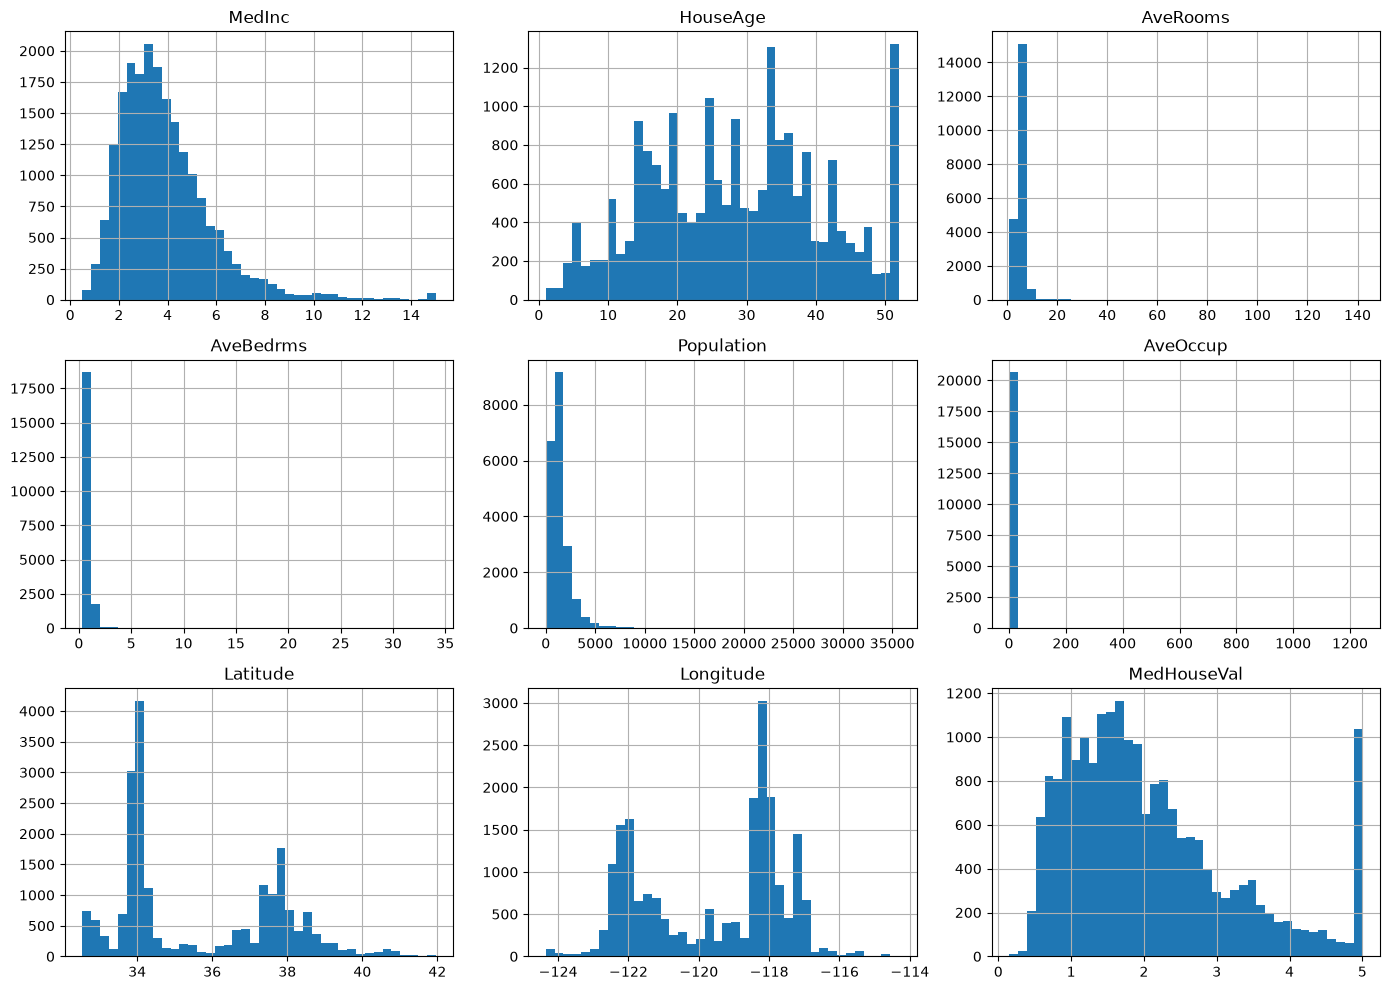

In [6]:
df.hist(bins=40, figsize=(14, 10))
plt.tight_layout()
plt.show()

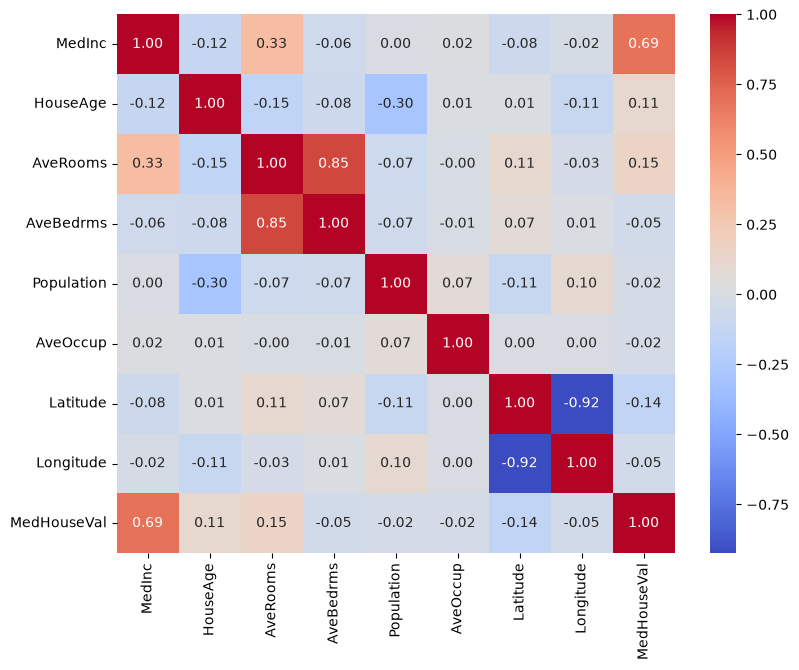

MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64

In [7]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()
df.corr()["MedHouseVal"].sort_values(ascending=False)

In [8]:
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f"MAE: {mae:.3f}  RMSE: {rmse:.3f}  R2: {r2:.3f}")

pd.Series(model.coef_, index=X.columns).sort_values()

MAE: 0.533  RMSE: 0.746  R2: 0.576


Longitude    -0.433708
Latitude     -0.419792
AveRooms     -0.123323
AveOccup     -0.003526
Population   -0.000002
HouseAge      0.009724
MedInc        0.448675
AveBedrms     0.783145
dtype: float64

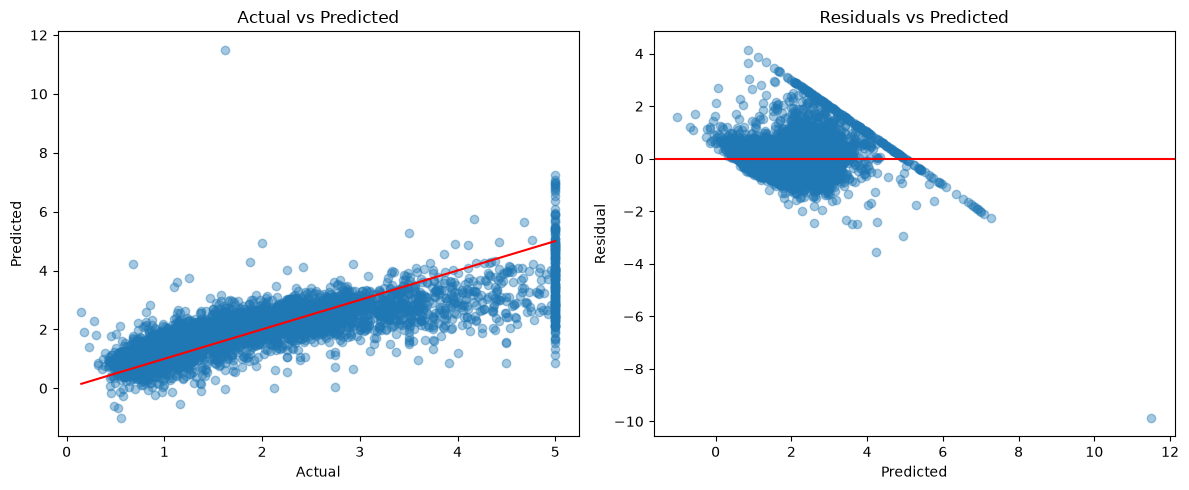

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(y_test, y_pred, alpha=0.4)
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
ax[0].set_xlabel("Actual")
ax[0].set_ylabel("Predicted")
ax[0].set_title("Actual vs Predicted")

ax[1].scatter(y_pred, y_test - y_pred, alpha=0.4)
ax[1].axhline(0, color="red")
ax[1].set_xlabel("Predicted")
ax[1].set_ylabel("Residual")
ax[1].set_title("Residuals vs Predicted")

plt.tight_layout()
plt.show()

In [10]:
with open("linear_regression_model.pkl", "wb") as f:
    pickle.dump(model, f)

with open("linear_regression_model.pkl", "rb") as f:
    loaded = pickle.load(f)

sample = pd.DataFrame([{
    "MedInc": 5.0, "HouseAge": 20, "AveRooms": 6.0, "AveBedrms": 1.0,
    "Population": 1200, "AveOccup": 3.0, "Latitude": 34.0, "Longitude": -118.0
}])
print("Predicted value (x $100,000):", loaded.predict(sample)[0])

Predicted value (x $100,000): 2.3493794640365024


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [12]:
data = fetch_california_housing(as_frame=True)
df = pd.concat([data.data, data.target.rename("HousePrice")], axis=1)
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,HousePrice
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [13]:
print(df.shape)
df.info()
print(df.isnull().sum())
df.describe().T

(20640, 9)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   HousePrice  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
HousePrice    0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
HousePrice,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


In [14]:
X = df.drop("HousePrice", axis=1)
y = df["HousePrice"]

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [16]:
print(X_train.describe().loc[["min", "max", "std"]].T)   # very different ranges

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on train only
X_test_scaled = scaler.transform(X_test)

pd.DataFrame(X_train_scaled, columns=X.columns).describe().loc[["mean", "std"]].round(2)

                   min           max          std
MedInc        0.499900     15.000100     1.904294
HouseAge      1.000000     52.000000    12.602499
AveRooms      0.888889    141.909091     2.387375
AveBedrms     0.333333     25.636364     0.433215
Population    3.000000  35682.000000  1137.056380
AveOccup      0.692308   1243.333333    11.578744
Latitude     32.550000     41.950000     2.136665
Longitude  -124.350000   -114.310000     2.005654


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
mean,-0.0,-0.0,0.0,-0.0,0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [17]:
models = {
    "Linear Regression": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
    "Ridge Regression":  Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]),
    "Decision Tree":     Pipeline([("scaler", StandardScaler()), ("model", DecisionTreeRegressor(max_depth=5, random_state=42))]),
}

In [18]:
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    cv_r2 = cross_val_score(model, X_train, y_train, cv=5, scoring="r2").mean()

    results[name] = {
        "Train RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "Test MAE": mean_absolute_error(y_test, test_pred),
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred),
        "CV R2 (5-fold)": cv_r2,
    }

results_df = pd.DataFrame(results).T.sort_values("Test RMSE").round(4)
results_df

,Train RMSE,Test RMSE,Test MAE,Train R2,Test R2,CV R2 (5-fold)
Decision Tree,0.6959,0.7242,0.5223,0.6377,0.5997,0.6198
Ridge Regression,0.7197,0.7456,0.5332,0.6126,0.5758,0.6115
Linear Regression,0.7197,0.7456,0.5332,0.6126,0.5758,0.6115


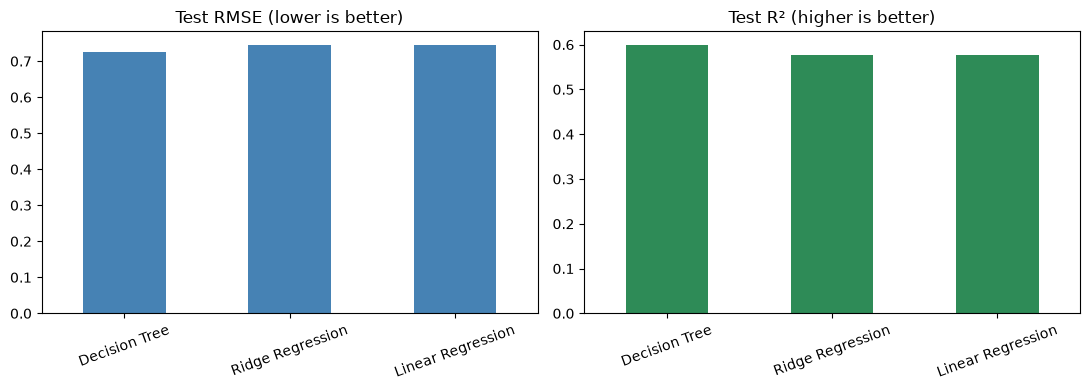

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
results_df["Test RMSE"].plot(kind="bar", ax=ax[0], color="steelblue", title="Test RMSE (lower is better)")
results_df["Test R2"].plot(kind="bar", ax=ax[1], color="seagreen", title="Test R² (higher is better)")
for a in ax:
    a.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

Best model: Decision Tree


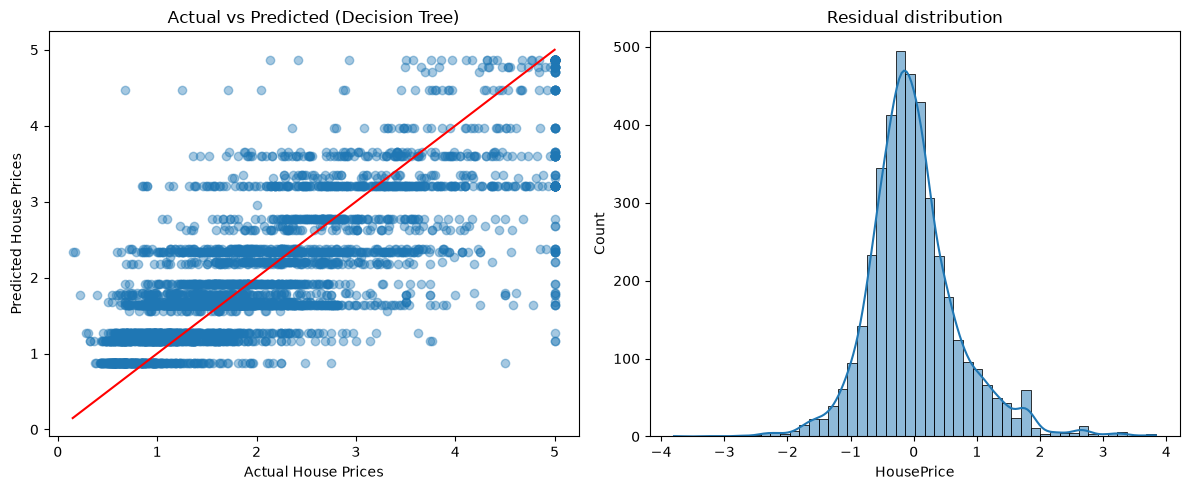

In [20]:
best_name = results_df["Test RMSE"].idxmin()
best_model = models[best_name]
print("Best model:", best_name)

y_pred = best_model.predict(X_test)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(y_test, y_pred, alpha=0.4)
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
ax[0].set_xlabel("Actual House Prices")
ax[0].set_ylabel("Predicted House Prices")
ax[0].set_title(f"Actual vs Predicted ({best_name})")

sns.histplot(y_test - y_pred, bins=50, kde=True, ax=ax[1])
ax[1].set_title("Residual distribution")

plt.tight_layout()
plt.show()

In [21]:
joblib.dump(best_model, "best_house_price_model.joblib")
loaded = joblib.load("best_house_price_model.joblib")
print(loaded.predict(X_test.iloc[:3]))

[1.16857267 1.27158128 3.19958174]


In [22]:
joblib.dump(best_model, "best_house_price_model.joblib")
loaded = joblib.load("best_house_price_model.joblib")
print(loaded.predict(X_test.iloc[:3]))

[1.16857267 1.27158128 3.19958174]
